# An LLM as a recommender, after Netflix's GenRec

Netflix's GenRec (Li et al. 2026, [arXiv:2608.10257](https://arxiv.org/abs/2608.10257)) replaces a ranker built on thousands of hand-made features
with an LLM that reads a member's watch history **as text** and scores the candidate titles.
Netflix adapted a large model to its own data, then post-trained it on ranking labels.

This notebook tries the bare idea with a small open model and **no training at all**, to see what the LLM brings by itself:

1. Write a user's favourite movies out as a sentence.
2. Hide the next movie they liked among nine other movies.
3. Score each candidate by how likely the model finds its title after the sentence, and rank.

**Data and models:**

- [MovieLens 100K](https://grouplens.org/datasets/movielens/100k/) (GroupLens, University of Minnesota). Research and teaching use, cite Harper and Konstan, ACM TiiS 2015, no redistribution, so it is downloaded (5 MB).
- [Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct) (Apache-2.0, 1 GB). About 10 minutes on a laptop CPU, under a minute on a GPU.
- When the course's automatic tests run this notebook (`COURSE_SMOKE=1`), the smaller [SmolLM2-135M-Instruct](https://huggingface.co/HuggingFaceTB/SmolLM2-135M-Instruct) (Apache-2.0) ranks for fewer users.

Collaborative filtering and content-based ranking on the same data are in `week5-surprise.ipynb`.

In [1]:
import io
import os
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# The course's automatic tests set COURSE_SMOKE=1: a smaller model and fewer users
SMOKE = os.environ.get("COURSE_SMOKE") == "1"
MODEL = "HuggingFaceTB/SmolLM2-135M-Instruct" if SMOKE else "Qwen/Qwen2.5-0.5B-Instruct"
N_USERS = 15 if SMOKE else 100
N_CANDIDATES = 10  # the movie the user liked next, plus 9 others

device = "cuda" if torch.cuda.is_available() else "cpu"
rng = np.random.default_rng(0)

## 1. The data

In [2]:
if not os.path.exists("ml-100k.zip"):
    urllib.request.urlretrieve("https://files.grouplens.org/datasets/movielens/ml-100k.zip", "ml-100k.zip")
archive = zipfile.ZipFile("ml-100k.zip")
ratings = pd.read_csv(io.BytesIO(archive.read("ml-100k/u.data")), sep="\t",
                      names=["user", "movie", "rating", "timestamp"])
titles = pd.read_csv(io.BytesIO(archive.read("ml-100k/u.item")), sep="|", encoding="latin-1",
                     header=None, usecols=[0, 1], names=["movie", "title"]).set_index("movie")["title"]
popularity = ratings.groupby("movie").size()  # how many people rated each movie
print(f"{len(ratings):,} ratings of {len(titles):,} movies by {ratings.user.nunique()} users")

100,000 ratings of 1,682 movies by 943 users


## 2. The task

For each user, take the **last** movie they rated 4 or 5: that is the movie to find.
Their history is the 10 movies they rated 4 or 5 just before it.
The other 9 candidates are random movies at least 50 people rated (so the model has a chance of knowing them) that this user never rated.

A ranker that guesses at random puts the hidden movie in its top 3 three times in ten.

In [3]:
known = popularity[popularity >= 50].index.to_numpy()
tasks = []
for user in rng.permutation(ratings.user.unique()):
    mine = ratings[ratings.user == user].sort_values("timestamp")
    liked = mine[mine.rating >= 4]
    if len(liked) < 11:
        continue
    target = liked.movie.iloc[-1]
    history = liked.movie.iloc[-11:-1].tolist()
    others = rng.choice(np.setdiff1d(known, mine.movie), N_CANDIDATES - 1, replace=False)
    tasks.append({"user": user, "history": history, "target": target,
                  "candidates": [target, *others]})  # the target is candidate 0
    if len(tasks) == N_USERS:
        break
print(len(tasks), "users")

100 users


## 3. Verbalise the history

GenRec's big change is that the input is text, not a feature vector. Here is one user's history as the model will read it:

In [4]:
def verbalise(history):
    return ("Movies this viewer loved: " + "; ".join(titles[m] for m in history)
            + ".\nThe next movie they watched and loved:")


print(verbalise(tasks[0]["history"]))

Movies this viewer loved: Secrets & Lies (1996); Long Kiss Goodnight, The (1996); Primal Fear (1996); Face/Off (1997); Close Shave, A (1995); Toy Story (1995); That Thing You Do! (1996); Anne Frank Remembered (1995); People vs. Larry Flynt, The (1996); Trainspotting (1996).
The next movie they watched and loved:


## 4. Score the candidates

For each candidate the model reads the prompt followed by the title, in one forward pass.
The score is the average log-probability of the title's tokens: how natural the model finds that title as the next movie.
All candidates for a user go through together, as a batch. Nothing is generated.
GenRec's "prefill-only" serving uses the same trick to rank many candidates in one pass.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).to(device).eval()
pad = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id


@torch.no_grad()
def score(prompt, movies):
    "Average log-probability of each movie's title after the prompt."
    prompt_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    sequences = [prompt_ids + tokenizer(" " + titles[m], add_special_tokens=False)["input_ids"] for m in movies]
    length = max(map(len, sequences))
    ids = torch.full((len(sequences), length), pad)
    mask = torch.zeros_like(ids)
    for row, seq in enumerate(sequences):
        ids[row, :len(seq)] = torch.tensor(seq)
        mask[row, :len(seq)] = 1
    ids, mask = ids.to(device), mask.to(device)
    log_probs = model(input_ids=ids, attention_mask=mask).logits[:, :-1].log_softmax(-1)
    token_log_probs = log_probs.gather(2, ids[:, 1:, None])[..., 0]  # log-prob of each actual next token
    is_title = mask[:, 1:].clone()
    is_title[:, :len(prompt_ids) - 1] = 0  # count only the title's tokens
    return ((token_log_probs * is_title).sum(1) / is_title.sum(1)).cpu().numpy()


task = tasks[0]
s = score(verbalise(task["history"]), task["candidates"])
pd.DataFrame({"candidate": [titles[m] + (" <- the one they liked" if m == task["target"] else "")
                            for m in task["candidates"]], "score": s.round(2)}).sort_values("score", ascending=False)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

,candidate,score
6,Mars Attacks! (1996),-1.59
4,She's the One (1996),-1.77
0,Grosse Pointe Blank (1997) <- the one they liked,-1.82
9,"Lost World: Jurassic Park, The (1997)",-1.83
3,Four Rooms (1995),-2.25
7,Addicted to Love (1997),-2.32
2,"Wrong Trousers, The (1993)",-2.44
1,Murder at 1600 (1997),-2.60
5,Nikita (La Femme Nikita) (1990),-2.90
8,Marvin's Room (1996),-3.06


## 5. Evaluate

Four rankers on the same tasks. The fourth is a **control**: the LLM reads *another* user's history.
If the control does as well as the LLM with the real history, the model is ranking titles it finds familiar, not reading the user's taste.

- **Hit at 3:** how often the hidden movie is in the top 3.
- **MRR** (mean reciprocal rank): 1 if it is first, 1/2 if second, and so on, averaged over users.

Qwen/Qwen2.5-0.5B-Instruct, 100 users, 10 candidates each
                             hit at 3   MRR
Random                           0.28  0.29
Popularity                       0.47  0.44
LLM, the user's history          0.35  0.32
LLM, someone else's history      0.35  0.29


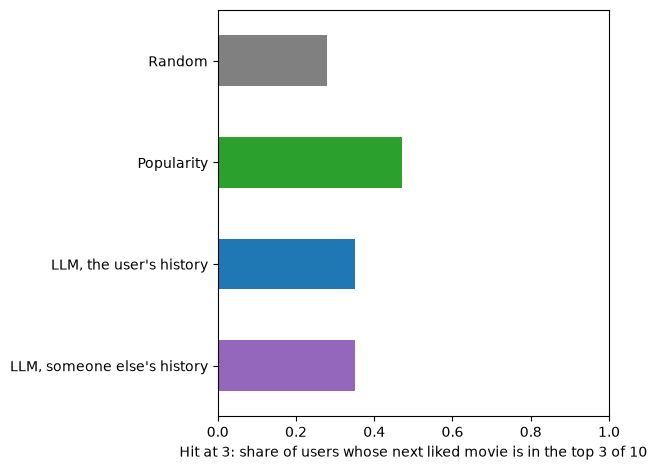

In [6]:
def rank_of_target(scores):
    "1 if the target (candidate 0) has the highest score."
    return 1 + int((scores > scores[0]).sum())


ranks = {"Random": [], "Popularity": [], "LLM, the user's history": [], "LLM, someone else's history": []}
for n, task in enumerate(tasks):
    other = tasks[(n + 1) % len(tasks)]["history"]
    candidates = task["candidates"]
    ranks["Random"].append(rank_of_target(rng.random(len(candidates))))
    counts = popularity[candidates].to_numpy(float)
    counts[0] -= 1  # leave out this user's own rating of the hidden movie
    ranks["Popularity"].append(rank_of_target(counts))
    ranks["LLM, the user's history"].append(rank_of_target(score(verbalise(task["history"]), candidates)))
    ranks["LLM, someone else's history"].append(rank_of_target(score(verbalise(other), candidates)))

results = pd.DataFrame({name: {"hit at 3": np.mean(np.array(r) <= 3), "MRR": np.mean(1 / np.array(r))}
                        for name, r in ranks.items()}).T
print(f"{MODEL}, {len(tasks)} users, {N_CANDIDATES} candidates each")
print(results.round(2).to_string())

ax = results["hit at 3"].plot.barh(color=["grey", "tab:green", "tab:blue", "tab:purple"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Hit at 3: share of users whose next liked movie is in the top 3 of 10")
plt.tight_layout()
plt.show()

## What this shows

With 100 users, a difference of less than about 0.1 in hit at 3 is noise.
At full size (Qwen2.5-0.5B, 100 users) we got: random 0.28, popularity 0.47, the LLM with the user's history 0.35, and with someone else's history 0.35.

- **The untrained LLM barely beats random guessing, and plain popularity beats it clearly.**
- **The control is the key result:** with someone else's history the LLM does just as well. It is ranking titles it finds familiar, not reading this user's taste.
- That is the gap GenRec closes with training. Netflix adapts the model to its catalogue and members, then post-trains it on ranking labels.
- What the text interface buys is flexibility: history, time of day, device or a typed request all go in the same prompt, with no new feature pipeline.

Try:

- A bigger model (`Qwen/Qwen2.5-1.5B-Instruct`), or one that knows more films.
- Put the ratings and years in the prompt, or list the movies the user disliked.
- Harder candidates: other movies from the same year or genre.
- Fine-tune the model on other users' histories (the post-training step), and test on held-out users.